In [80]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from monai.transforms import LoadImage, Resize, EnsureChannelFirst, Orientation, Compose, SaveImage, Transform
from monai.bundle import ConfigParser, download
from monai.data.meta_tensor import MetaTensor
import torch
import torch.nn as nn
import torch.nn.functional as F
import seaborn as sns
from ipywidgets import interact
import nibabel as nib
from nibabel import Nifti1Image
from totalsegmentator.python_api import totalsegmentator
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader, random_split
import torch.optim as optim
import lightning as L
from lightning.pytorch import Trainer
from lightning.pytorch.callbacks import EarlyStopping
import pandas as pd
import torchmetrics
from torchmetrics.classification import BinaryAccuracy, BinaryPrecision, BinaryRecall, BinaryF1Score, BinaryConfusionMatrix, BinarySpecificity
from torchview import draw_graph



In [82]:
%matplotlib inline

def show_scrollable_image(image, cmap="nipy_spectral"):
    """
    Displays a 3D array as a scrollable series of slices.
    
    Parameters:
    - image (numpy.ndarray): A 3D numpy array (e.g., (H, W, D)) representing the image.
    """
    
    # Define a function to display each slice
    def display_slice(slice_index):
        plt.figure(figsize=(8, 8))
        plt.imshow(image[:, :, slice_index], cmap=cmap)
        plt.colorbar(label='HU')
        plt.axis("off")
        plt.title(f"Slice {slice_index + 1} / {image.shape[2]}")
        plt.show()
    
    # Create an interactive slider to scroll through slices
    interact(display_slice, slice_index=(0, image.shape[2] - 1))

In [83]:
def nifti1image_to_metatensor(nifti_img: Nifti1Image) -> MetaTensor:
    """
    Converts a Nifti1Image object to a MetaTensor with metadata.
    Args:
        nifti_img (Nifti1Image): A loaded NIfTI image.
    Returns:
        MetaTensor: A MONAI MetaTensor containing the image data and metadata.
    """
    # Convert voxel data to PyTorch tensor
    image_tensor = torch.tensor(nifti_img.get_fdata(), dtype=torch.float32)

    # Extract metadata
    metadata = {
        "affine": torch.tensor(nifti_img.affine, dtype=torch.float32),  # Affine transformation matrix
        "spacing": nifti_img.header.get_zooms(),  # Voxel spacing (x, y, z)
        "original_shape": image_tensor.shape  # Store original shape for reference
    }

    # Create a MetaTensor with metadata
    meta_tensor = MetaTensor(image_tensor, meta=metadata)

    return meta_tensor

In [84]:
def resize_to_target_slices(image: MetaTensor, heart_mask: MetaTensor, target_width=512, target_height=512, target_slices=128):
    """
    Extracts the heart region from the input scan and resizes it to a target number of slices, 
    preserving metadata while correctly computing voxel spacing.

    Args:
        image (MetaTensor): The input 3D CT/MRI scan.
        heart_mask (MetaTensor): Binary mask indicating heart region.
        target_slices (int, optional): Number of slices to resize to. Default is 128.

    Returns:
        MetaTensor: Resized image with updated metadata.
    """
    if isinstance(heart_mask, MetaTensor):
        heart_mask = heart_mask.as_tensor().cpu().numpy()
    
    z_indices = np.any(heart_mask > 0, axis=(0, 1))
    heart_slices = np.where(z_indices)[0]
    # print(heart_slices)
    if len(heart_slices) == 0:
        raise ValueError("No heart region found in the mask.")
    
    start_slice = heart_slices[0]
    end_slice = heart_slices[-1] + 1
    
    sliced_image = image[:, :, start_slice:end_slice]
    if not isinstance(sliced_image, MetaTensor):
        sliced_image = MetaTensor(sliced_image, meta=image.meta)
    
    height, width, original_depth = image.shape
    # sliced_depth = sliced_image.shape[-1]

    sliced_image = sliced_image.unsqueeze(0)  # Shape becomes (1, H, W, Z)
    
    resizer = Resize(spatial_size=(target_width,target_height,target_slices), mode="trilinear", align_corners=True)
    resized_image = resizer(sliced_image)
    
    resized_image = resized_image.squeeze(0)

    # Update metadata
    new_meta = image.meta.copy()  
    
    original_spacing = image.meta.get("spacing", (1.0, 1.0, 1.0))
    new_spacing = (
        original_spacing[0],
        original_spacing[1],
        original_spacing[2] * (original_depth / target_slices)
    )
    new_meta["spacing"] = new_spacing

    # Keep affine transformation matrix but adjust slice resolution
    if "affine" in new_meta:
        new_meta["affine"][-1, -1] *= (original_depth / target_slices)  # Adjust Z scaling

    # Return resized MetaTensor with updated metadata
    return MetaTensor(resized_image, meta=new_meta)

In [85]:
def align_segmentation_to_image(segmentation):
    """
    Aligns the TotalSegmentator output (segmentation) with the original image
    by flipping the z-axis of the segmentation mask.
    
    Parameters:
        image (torch.Tensor or np.ndarray): Original image (H x W x D).
        segmentation (torch.Tensor or np.ndarray): TotalSegmentator output (H x W x D).
        
    Returns:
        torch.Tensor: Segmentation aligned with the image.
    """
   
    # Flip along the z-axis (last dimension)
    aligned_segmentation = torch.flip(segmentation, dims=[-1])
    
    return aligned_segmentation

# Example usage
# aligned_mask = align_segmentation_to_image(full_image)



In [86]:
def custom_name_formatter(metadict: dict, saver: Transform) -> dict:
    """Returns a kwargs dict for :py:meth:`FolderLayout.filename`,
    according to the input metadata and SaveImage transform."""
    subject = "heart_resized"
    patch_index = None
    return {"subject": f"{subject}", "idx": patch_index}

In [87]:
def preprocess_full_heart(input_file_path: str):
    # input_folder = f"../data/Inputs/{input_file_path}"
    dicom_file_path = os.path.join(input_file_path, "DICOM")
    subfolders = sorted([f for f in os.listdir(dicom_file_path) if os.path.isdir(os.path.join(dicom_file_path, f))])
    
    if not subfolders:
        raise FileNotFoundError(f"No subfolders found in {dicom_file_path}")
    
    first_folder = subfolders[0]
    dicom_file_path = os.path.join(dicom_file_path, first_folder)    

    output_folder = input_file_path.replace("Inputs", "Outputs")
    
    if os.path.exists(f"{output_folder}/heart_resized.nii.gz"):
        image_loader = LoadImage(image_only=True, ensure_channel_first=True)
        resized_image = image_loader(f"{output_folder}/heart_resized.nii.gz")
        resized_image = resized_image.squeeze(dim=-1)
        # resized_image = resize_to_target_slices(output_image, output_image)
        # resized_image = nib.load(f"{output_folder}/heart_resized.nii.gz")
    else:
        # output_image = totalsegmentator(dicom_file_path, output_folder, license_number="aca_BWYHC6UQQFDU8A", roi_subset=["heart"], device="mps")
        output_image = totalsegmentator(dicom_file_path, output_folder, roi_subset=["heart"], device="mps")
        output_image = nifti1image_to_metatensor(output_image)
        resized_image = resize_to_target_slices(output_image, output_image,target_height=64,target_width=64,target_slices=64)
        # nib.save(resized_image, f"{output_folder}/heart_resized.nii.gz")
        print("saving")
        image_saver = SaveImage(output_dir=f"{output_folder}", separate_folder=False, output_postfix="", output_name_formatter=custom_name_formatter)
        image_saver(resized_image)
        print("saved")
        print(resized_image.shape)
    
    return resized_image
    


# preprocess_full_heart("takotsubo_cases/testing_subset/LET 04456356")


In [88]:
x_data = []
metadata = []
y_labels = []

In [89]:
takotsubo_data_path = '../data/Inputs/takotsubo_cases/'

# Load metadata CSV
metadata_df = pd.read_csv("takotsubo_cases_metadata.csv")

# Convert DataFrame into a dictionary for quick lookup
metadata_dict = metadata_df.set_index("PatientID").to_dict(orient="index")

print("✅ Metadata loaded successfully!")

# takotsubo_preprocessed_data = []
missing_ids = []

for folder_name in sorted(os.listdir(takotsubo_data_path)):
    patient_id = folder_name
    folder_path = os.path.join(takotsubo_data_path, folder_name)
    if os.path.isdir(folder_path):
        if patient_id in metadata_dict:
            print(f"Processing: {patient_id}")
            preprocessed_heart = preprocess_full_heart(folder_path)
            x_data.append(preprocessed_heart)
            metadata.append([metadata_dict[patient_id]["Age"], metadata_dict[patient_id]["Gender"]])
            y_labels.append(1)
        else:
            print(f"⚠️ Warning: No metadata found for '{patient_id}'. Skipping...")
            missing_ids.append(patient_id)

if missing_ids:
    with open("missing_metadata_ids.txt", "w") as f:
        f.write("\n".join(missing_ids))
    print(f"⚠️ Missing metadata for {len(missing_ids)} patients. Logged to 'missing_metadata_ids.txt'.")


✅ Metadata loaded successfully!
Processing: AD 12191953
Processing: AG 11370442
Processing: AMH 36922300
Processing: AMS 22722383
Processing: APH 3516218
Processing: BB 8903260
Processing: BEH 4037842
Processing: BFM 10624765
Processing: BLT 11022191
Processing: CAMcD 10747764
Processing: CDA 38093134
Processing: CLB 50002879
Processing: CML 11113354
Processing: CMS 4664231
Processing: DCA 9939935
Processing: DD 26362236
Processing: DEM 9902248
Processing: DIW 10053411
Processing: DJD 6122410
Processing: DJK 2493
Processing: DJM 34687566
Processing: ECW 33674557
Processing: EIC 26844753
Processing: ELD 30527501
Processing: EMB 34404780
Processing: FFJ 11086170
Processing: GA 39800503
Processing: GAB 25512591
Processing: GB 10468072
Processing: GHM 4514352
Processing: GJB 30653190
Processing: GJI 25633926
Processing: HSM 3468857
Processing: IK 6526404
Processing: JAL 6996466
Processing: JAQ 3124096
Processing: JD 48020
Processing: JDMB 13788
Processing: JDMB 137882
Processing: JEB 61239

In [90]:
normal_data_path = '../data/Inputs/normal_cases/'

metadata_df = pd.read_csv("normal_cases_metadata.csv")

# Convert DataFrame into a dictionary for quick lookup
metadata_dict = metadata_df.set_index("PatientID").to_dict(orient="index")

print("✅ Metadata loaded successfully!")

# normal_preprocessed_data = []
for folder_name in sorted(os.listdir(normal_data_path)):
    patient_id = folder_name.split('_')[0]
    folder_path = os.path.join(normal_data_path, folder_name)
    if os.path.isdir(folder_path):
        print(folder_path)
        preprocessed_heart = preprocess_full_heart(folder_path)
        x_data.append(preprocessed_heart)
        metadata.append([metadata_dict[patient_id]["Age"], metadata_dict[patient_id]["Gender"]])
        y_labels.append(0)

✅ Metadata loaded successfully!
../data/Inputs/normal_cases/AAP 50415783_61F
../data/Inputs/normal_cases/AB 10470318_90F
../data/Inputs/normal_cases/AG 519880_37F
../data/Inputs/normal_cases/AIB 36444628_88F
../data/Inputs/normal_cases/AMB 08058471_74M
../data/Inputs/normal_cases/ASJ 05633540_68F
../data/Inputs/normal_cases/ASSA 39309711_56F
../data/Inputs/normal_cases/BA 37586690_62M
../data/Inputs/normal_cases/BJB 42898_78F
../data/Inputs/normal_cases/BMB 26209098_65M
../data/Inputs/normal_cases/BWB 08372559_71M
../data/Inputs/normal_cases/CAB 30473847_51F
../data/Inputs/normal_cases/CAD 35811017_49F
../data/Inputs/normal_cases/CAM 29734621_78F
../data/Inputs/normal_cases/CB 11607017_75F
../data/Inputs/normal_cases/CEEB 08099780_60F
../data/Inputs/normal_cases/CEK 02226835_80F
../data/Inputs/normal_cases/CMLB 50124639_67F
../data/Inputs/normal_cases/DAB 37356987_82F
../data/Inputs/normal_cases/DB 24229841_67F
../data/Inputs/normal_cases/DCE 22600738_50M
../data/Inputs/normal_cases/DE

In [91]:
class CTScanDataset(Dataset):
    def __init__(self, images, metadata, labels):
        self.images = images.float().unsqueeze(1)  # (N, 1, H, W, D)
        self.metadata = torch.tensor(metadata, dtype=torch.float32)  # (N, 2) - Age & Gender
        self.labels = torch.tensor(labels, dtype=torch.float32).unsqueeze(1)  # (N, 1)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.metadata[idx], self.labels[idx]

# Convert MetaTensors to regular tensors
x_data = torch.stack([x.as_tensor() for x in x_data])  # (N, 512, 512, 128)
y_labels = torch.tensor(y_labels, dtype=torch.float32)

# Create dataset
dataset = CTScanDataset(x_data, metadata, y_labels)



/var/folders/jm/k37qm_7n7dj5fp2rnwhd32y80000gn/T/ipykernel_68762/1583307501.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.labels = torch.tensor(labels, dtype=torch.float32).unsqueeze(1)  # (N, 1)


In [92]:
takotsubo_count = sum(1 for y in dataset if y[2] == 1)
normal_count = sum(1 for y in dataset if y[2] == 0)
print(f"📊 Dataset Distribution - Takotsubo: {takotsubo_count}, Normal: {normal_count}")

📊 Dataset Distribution - Takotsubo: 91, Normal: 76


In [93]:
class CTScanDataModule(L.LightningDataModule):
    def __init__(self, dataset, batch_size=1, train_split=0.70, val_split=0.1, test_split=0.2):
        super().__init__()
        self.dataset = dataset
        self.batch_size = batch_size
        self.train_split = train_split
        self.val_split = val_split
        self.test_split = test_split
        
    def setup(self, stage=None):
        total_size = len(self.dataset)
        train_size = int(self.train_split * total_size)
        val_size = int(self.val_split * total_size)
        test_size = total_size - train_size - val_size  # Ensure total adds up
        
        self.train_dataset, self.val_dataset, self.test_dataset = random_split(self.dataset, [train_size, val_size, test_size])
        print(f"📊 Total dataset size: {len(self.dataset)}")
        print(f"📂 Train set size: {len(self.train_dataset)}")
        print(f"📂 Validation set size: {len(self.val_dataset)}")
        print(f"📂 Test set size: {len(self.test_dataset)}")

    def train_dataloader(self):
        return DataLoader(self.train_dataset, batch_size=self.batch_size, shuffle=True, num_workers=0)

    def val_dataloader(self):
        return DataLoader(self.val_dataset, batch_size=self.batch_size, shuffle=False, num_workers=0)
    
    def test_dataloader(self):
        return DataLoader(self.test_dataset, batch_size=self.batch_size, shuffle=False, num_workers=0)


In [94]:
from sympy import false


class CNN3D(L.LightningModule):
    def __init__(self, learning_rate=0.0001):
        super().__init__()
        self.learning_rate = learning_rate
        
        self.accuracy = BinaryAccuracy()
        self.precision = BinaryPrecision(zero_division=0)
        self.recall = BinaryRecall(zero_division=0)
        self.f1_score = BinaryF1Score(zero_division=0)
        self.specificity = BinarySpecificity(zero_division=0)
        self.conf_matrix = BinaryConfusionMatrix()
        
        self.all_preds = []
        self.all_labels = []
        self.gradients = None  # Stores gradients
        self.activations = None  # Stores feature maps

        self.conv1 = nn.Conv3d(1, 16, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool3d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv3d(16, 32, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv3d(32, 64, kernel_size=3, stride=1, padding=1)

        self.global_pool = nn.AdaptiveAvgPool3d((2, 2, 2))  # Output shape: (64, 2, 2, 2)

        # Fully connected layers for image features
        self.fc1 = nn.Linear(64 * 2 * 2 * 2, 128)
        self.dropout = nn.Dropout(p=0.3)

        # Fully connected layer for metadata input (Age + Gender)
        self.fc_metadata = nn.Linear(2, 16)  # 2 features: Age & Gender

        # Final classification layer (combining image + metadata)
        self.fc2 = nn.Linear(128 + 16, 1)

        self.criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(91/76))  # Binary classification loss
        

    def forward(self, image, metadata):
        x = torch.relu(self.conv1(image))
        x = self.pool(x)
        x = torch.relu(self.conv2(x))
        x = self.pool(x)
        x = torch.relu(self.conv3(x))

        if self.training:  
            self.activations = x  # Store feature maps
            x.register_hook(self.save_gradient)
        
        x = self.pool(x)
        
    
        x = self.global_pool(x)
        x = torch.flatten(x, start_dim=1)

        x = torch.relu(self.fc1(x))
        x = self.dropout(x)


        # Process metadata separately
        meta_x = torch.relu(self.fc_metadata(metadata))

        # Concatenate image and metadata features
        x = torch.cat((x, meta_x), dim=1)

        # Final classification
        x = self.fc2(x)
        # x = self.dropout(x)
        return x

    def save_gradient(self, grad):
        self.gradients = grad

    def training_step(self, batch, batch_idx):
        images, metadata, labels = batch
        labels = labels.float()
        outputs = self(images, metadata)
        loss = self.criterion(outputs, labels)
        self.log("train_loss", loss, prog_bar=True, on_step=True)
        return loss
    
    def on_train_epoch_end(self):
        optimizer = self.trainer.optimizers[0]  # Get optimizer
        current_lr = optimizer.param_groups[0]["lr"]  # Fetch updated LR
        print(f"Learning Rate after epoch {self.current_epoch}: {current_lr}")

        # Log updated learning rate to Lightning
        self.log("learning_rate", current_lr, prog_bar=True)

    def validation_step(self, batch, batch_idx):
        images, metadata, labels = batch
        labels = labels.float()
        outputs = self(images, metadata)
        loss = self.criterion(outputs, labels)
        preds = (outputs > 0.5).float()
        # acc = (preds == labels).float().mean()
        acc = self.accuracy(preds, labels)
        f1_score = self.f1_score(preds, labels)
        self.log("val_loss", loss, prog_bar=True, on_step=False, on_epoch=True)
        self.log("val_acc", self.accuracy, prog_bar=True, on_step=False, on_epoch=True)
        self.log("val_f1", self.f1_score, prog_bar=True, on_step=False, on_epoch=True)

        return loss
    
    def on_test_epoch_start(self):
        self.precision.reset()
        self.recall.reset()
        self.f1_score.reset()

    
    def test_step(self, batch, batch_idx):
        images, metadata, labels = batch
        labels = labels.float()
        outputs = self(images, metadata)
        loss = self.criterion(outputs, labels)
        preds = (outputs > 0.5).float()
    
        # print(f"Batch {batch_idx} - Raw Outputs: {outputs.flatten().tolist()}")
        # print(f"Batch {batch_idx} - Predictions: {preds.flatten().tolist()}")
        # print(f"Batch {batch_idx} - Labels: {labels.flatten().tolist()}")
            
        acc = self.accuracy(preds, labels)
        precision = self.precision(preds, labels)
        recall = self.recall(preds, labels)
        f1_score = self.f1_score(preds, labels)
        specificity = self.specificity(preds, labels)
        # cm = self.conf_matrix(preds, labels)
        
        self.all_preds.append(preds)
        self.all_labels.append(labels)

        # 🔹 Log metrics
        self.log("test_loss", loss, prog_bar=True, on_step=False, on_epoch=True)
        self.log("test_acc", self.accuracy, prog_bar=True, on_step=False, on_epoch=True)
        self.log("test_precision", self.precision, prog_bar=True, on_step=False, on_epoch=True)
        self.log("test_recall", self.recall, prog_bar=True, on_step=False, on_epoch=True)
        self.log("test_f1", self.f1_score, prog_bar=True, on_step=False, on_epoch=True)
        self.log("test_specificity", self.specificity, prog_bar=True, on_step=False, on_epoch=True)
        

        # print(f"Batch {batch_idx} - Confusion Matrix:\n{cm.cpu().numpy()}")

        return loss
    
    def on_test_epoch_end(self):
        """🔹 Compute and log final Confusion Matrix at the end of testing."""
        all_preds = torch.cat(self.all_preds).to(self.device)  # Move to device
        all_labels = torch.cat(self.all_labels).to(self.device)  # Move to device

        # Compute final confusion matrix
        cm = self.conf_matrix(all_preds, all_labels)

        cm_numpy = cm.cpu().numpy()
        plt.figure(figsize=(5, 5))
        sns.heatmap(cm_numpy, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Takotsubo"], yticklabels=["Normal", "Takotsubo"])
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.title("Confusion Matrix of Test Data Predictions")
        plt.show()

        # print(f"Final Confusion Matrix:\n{cm_numpy}")

    def configure_optimizers(self):
        optimizer = optim.Adam(self.parameters(), lr=self.learning_rate)
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=3, factor=0.5)
        return {"optimizer": optimizer, "lr_scheduler": scheduler, "monitor": "val_loss"} 



In [95]:
# Initialize Model & DataModule
# pos_weight = torch.tensor([normal_count / takotsubo_count])
model = CNN3D(learning_rate=0.001)
data_module = CTScanDataModule(dataset, batch_size=1)

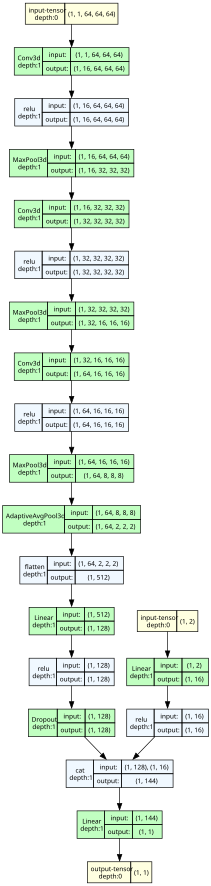

In [96]:
sample_image, sample_metadata, sample_label = dataset[0]  # Get image, metadata, label

# Move data to the same device as the model
sample_image = sample_image.unsqueeze(0)  # Add batch dimension
sample_metadata = sample_metadata.unsqueeze(0)  # Add batch dimension

# Generate visualization using real data
graph = draw_graph(model, input_data=(sample_image, sample_metadata), expand_nested=True, depth=4, graph_dir="TB", roll=False)
graph.visual_graph  # Displays the model structure

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs

   | Name        | Type                  | Params | Mode 
---------------------------------------------------------------
0  | accuracy    | BinaryAccuracy        | 0      | train
1  | precision   | BinaryPrecision       | 0      | train
2  | recall      | BinaryRecall          | 0      | train
3  | f1_score    | BinaryF1Score         | 0      | train
4  | specificity | BinarySpecificity     | 0      | train
5  | conf_matrix | BinaryConfusionMatrix | 0      | train
6  | conv1       | Conv3d                | 448    | train
7  | pool        | MaxPool3d             | 0      | train
8  | conv2       | Conv3d                | 13.9 K | train
9  | conv3       | Conv3d                | 55.4 K | train
10 | global_pool | AdaptiveAvgPool3d     | 0      | train
11 | fc1         | Linear                | 65.7 K | train
12 | dropout     | Dropout               | 0      | train
13 | fc_

📊 Total dataset size: 167
📂 Train set size: 116
📂 Validation set size: 16
📂 Test set size: 35


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/Users/awabakram/git/Takotsubo-Syndrome/myenv3/lib/python3.9/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.
/Users/awabakram/git/Takotsubo-Syndrome/myenv3/lib/python3.9/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Training: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Monitored metric val_loss did not improve in the last 6 records. Best score: 0.406. Signaling Trainer to stop.


Learning Rate after epoch 15: 0.0005

🚀 Running final test evaluation...

📊 Total dataset size: 167
📂 Train set size: 116
📂 Validation set size: 16
📂 Test set size: 35


/Users/awabakram/git/Takotsubo-Syndrome/myenv3/lib/python3.9/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Testing: |          | 0/? [00:00<?, ?it/s]

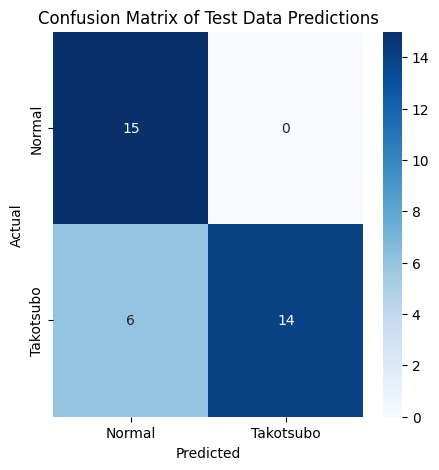

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_acc            0.8285714387893677
         test_f1            0.8235294222831726
        test_loss           0.38724541664123535
     test_precision                 1.0
       test_recall           0.699999988079071
    test_specificity                1.0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


[{'test_loss': 0.38724541664123535,
  'test_acc': 0.8285714387893677,
  'test_precision': 1.0,
  'test_recall': 0.699999988079071,
  'test_f1': 0.8235294222831726,
  'test_specificity': 1.0}]

In [97]:
%matplotlib inline
trainer = Trainer(max_epochs=20, accelerator="auto", log_every_n_steps=1, 
                  callbacks=[
                    EarlyStopping(
                        monitor="val_loss",  # Metric to track
                        patience=6,  # Stop if no improvement after 6 epochs
                        mode="min",  # "min" because lower loss is better
                        verbose=True
                    )
                    ]
                  )

# Train Model
trainer.fit(model, datamodule=data_module)

print("\n🚀 Running final test evaluation...\n")
trainer.test(model, datamodule=data_module)


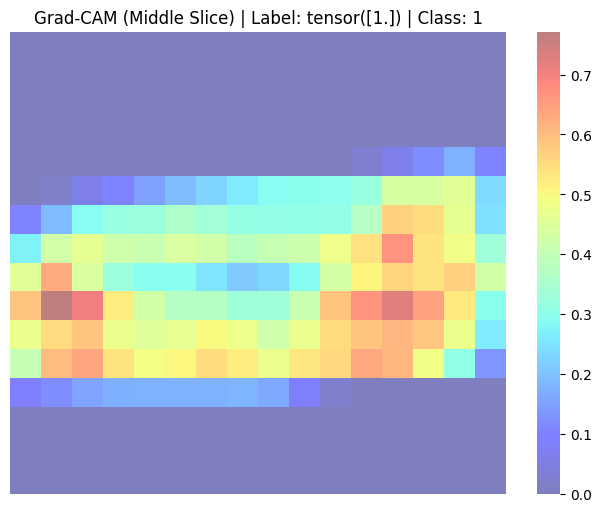

In [ ]:
# from torchcam.methods import GradCAM

# def generate_3d_grad_cam(model, image, metadata, label):
#     """Generates a Grad-CAM heatmap for a 3D CNN model."""
#     model.eval()

#     # Ensure image has correct shape
#     if image.dim() == 4:  
#         image = image.unsqueeze(0)  # Add batch dimension if missing

#     # Initialize Grad-CAM on last convolutional layer
#     cam_extractor = GradCAM(model, target_layer=model.conv3)

#     # Forward pass (needed for Grad-CAM hooks)
#     scores = model(image, metadata)  # Shape: [1, 1] (binary classification)

#     # Convert single score to a fake 2-class score for Grad-CAM
#     binary_scores = torch.cat([1 - torch.sigmoid(scores), torch.sigmoid(scores)], dim=1)  # Shape: [1, 2]
#     class_idx = int(binary_scores[0, 1] > 0.5)  # Select predicted class

#     # Run Grad-CAM
#     activation_map = cam_extractor(class_idx=class_idx, scores=binary_scores)[0]  # Extract first item

#     # Remove batch dimension
#     activation_map = activation_map.squeeze(0)  # Now shape is (D, H, W)

#     # Convert to NumPy
#     activation_map = activation_map.cpu().detach().numpy()

#     # Handle NaNs & Normalize
#     activation_map = np.nan_to_num(activation_map)  # Replace NaNs
#     min_val, max_val = np.min(activation_map), np.max(activation_map)
#     if max_val - min_val > 1e-8:  # Avoid dividing by zero
#         activation_map = (activation_map - min_val) / (max_val - min_val)

#     # Select **middle slice** along depth (D)
#     middle_slice = activation_map.shape[0] // 2  
#     heatmap_2d = activation_map[middle_slice, :, :]  # Extract middle slice

#     # Ensure it's valid for visualization
#     if heatmap_2d.ndim != 2:
#         print(f"⚠️ Error: Heatmap is not 2D! Shape: {heatmap_2d.shape}")
#     elif np.isnan(heatmap_2d).all():
#         print("⚠️ Warning: Activation map contains only NaN values!")
#     else:
#         # Plot heatmap
#         plt.figure(figsize=(8, 6))
#         sns.heatmap(heatmap_2d, cmap="jet", alpha=0.5)
#         plt.title(f"Grad-CAM (Middle Slice) | Label: {label} | Class: {class_idx}")
#         plt.axis("off")
#         plt.show()

# # Run Grad-CAM
# generate_3d_grad_cam(model, sample_image, sample_metadata, sample_label)


In [ ]:
# # Import M3d-CAM
# from medcam import medcam

# # 🔹 Wrapper function for medcam
# class MedCAMWrapper(nn.Module):
#     def __init__(self, model):
#         super().__init__()
#         self.model = model  # Store original model
    
#     def forward(self, batch):
#         """Extracts images and metadata from batch for proper forward pass."""
#         images, metadata, _ = batch  # Unpack batch (ignore labels)
#         return self.model(images, metadata)  # Correctly pass both inputs

# def generate_3d_grad_cam(model, batch):
#     """Generates a Grad-CAM heatmap for a 3D CNN model using M3d-CAM."""
    
#     # 🔹 Wrap model to make it compatible with medcam
#     med_model = MedCAMWrapper(model)

#     # 🔹 Inject M3d-CAM
#     med_model = medcam.inject(med_model, output_dir="attention_maps", save_maps=True)

#     # 🔹 Set to evaluation mode
#     med_model.eval()

#     # 🔹 Run forward pass (batch is correctly structured)
#     _ = med_model(batch)

#     print("Grad-CAM attention maps generated and saved in 'attention_maps' directory.")

# # Get a single batch from the test DataLoader
# batch = next(iter(data_module.test_dataloader()))

# # Run Grad-CAM
# generate_3d_grad_cam(model, batch)


AttributeError: 'list' object has no attribute 'shape'

In [ ]:
# import cv2
# import numpy as np
# import matplotlib.pyplot as plt

# def overlay_gradcam_on_ct(original_image, heatmap, alpha=0.5):
#     """ Overlays the Grad-CAM heatmap on the original CT scan slice. """
#     # Normalize original image to [0, 255] for visualization
#     original_image = original_image.cpu().detach().numpy()
#     original_image = (original_image - original_image.min()) / (original_image.max() - original_image.min())  # Normalize
#     original_image = (original_image * 255).astype(np.uint8)  # Convert to uint8

#     # Resize heatmap to match original image resolution
#     heatmap_resized = cv2.resize(heatmap, (original_image.shape[1], original_image.shape[0]), interpolation=cv2.INTER_CUBIC)

#     # Normalize heatmap correctly
#     heatmap_resized = (heatmap_resized - np.min(heatmap_resized)) / (np.max(heatmap_resized) - np.min(heatmap_resized) + 1e-8)
#     heatmap_resized = np.uint8(255 * heatmap_resized)  # Convert to uint8

#     # Debugging print
#     print("Heatmap dtype:", heatmap_resized.dtype, "Shape:", heatmap_resized.shape)

#     # Apply jet colormap
#     heatmap_color = cv2.applyColorMap(heatmap_resized, cv2.COLORMAP_JET)

#     # Convert grayscale original to 3-channel image
#     original_colored = cv2.cvtColor(original_image, cv2.COLOR_GRAY2BGR)

#     # Blend the heatmap and the original image
#     blended = cv2.addWeighted(original_colored, 1 - alpha, heatmap_color, alpha, 0)

#     # Display final overlay
#     plt.figure(figsize=(8, 6))
#     plt.imshow(blended)
#     plt.axis("off")
#     plt.title("Grad-CAM Overlay on CT Scan")
#     plt.show()

# def generate_3d_grad_cam(model, image, metadata, label):
#     """Generates a Grad-CAM heatmap for a 3D CNN model."""
#     model.eval()

#     # Ensure image has correct shape
#     if image.dim() == 4:  
#         image = image.unsqueeze(0)  # Add batch dimension if missing

#     # Initialize Grad-CAM on last convolutional layer
#     cam_extractor = GradCAM(model, target_layer=model.conv3)

#     # Forward pass
#     scores = model(image, metadata)  # Shape: [1, 1] (binary classification)

#     # Convert binary output to pseudo 2-class scores
#     binary_scores = torch.cat([1 - torch.sigmoid(scores), torch.sigmoid(scores)], dim=1)  # Shape: [1, 2]
#     class_idx = int(binary_scores[0, 1] > 0.5)  # Select predicted class

#     # Run Grad-CAM
#     activation_map = cam_extractor(class_idx=class_idx, scores=binary_scores)

#     # Convert to NumPy
#     activation_map = activation_map[0].cpu().detach().numpy()

#     # Handle NaNs & Normalize
#     activation_map = np.nan_to_num(activation_map)  # Replace NaNs
#     min_val, max_val = np.min(activation_map), np.max(activation_map)
#     if max_val - min_val > 1e-8:  # Avoid division by zero
#         activation_map = (activation_map - min_val) / (max_val - min_val)

#     # Extract the middle slice
#     middle_slice = activation_map.shape[0] // 2  
#     heatmap_2d = activation_map[middle_slice, :, :]  # Get middle slice

#     # Ensure valid visualization
#     if np.isnan(heatmap_2d).all():
#         print("⚠️ Warning: Activation map contains only NaN values!")
#     else:
#         # Extract the corresponding original CT slice
#         original_ct_slice = image[0, 0, :, :, middle_slice]  # Get same depth slice

#         # Overlay and visualize
#         overlay_gradcam_on_ct(original_ct_slice, heatmap_2d)


# # Run Grad-CAM with visualization
# generate_3d_grad_cam(model, sample_image, sample_metadata, sample_label)


Heatmap dtype: uint8 Shape: (64, 64, 16)


error: OpenCV(4.11.0) /Users/xperience/GHA-Actions-OpenCV/_work/opencv-python/opencv-python/opencv/modules/imgproc/src/colormap.cpp:736: error: (-5:Bad argument) cv::ColorMap only supports source images of type CV_8UC1 or CV_8UC3 in function 'operator()'
